In [292]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.datasets import fetch_california_housing
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split

In [294]:
casa = pd.read_excel("./Datasets/01 ProvidenceClean.xlsx")
casas = casa.select_dtypes(include=[np.number])
casas.columns = casas.columns.str.strip()
casas = casas.drop(columns=["TAX","GROSS AREA","LIVING AREA","YR BUILT","ROOMS","BEDROOMS","FLOORS","KITCHEN"])

In [295]:
matriz_correlacion = casas.corr()

In [298]:
caracteristicas_alta_correlacion = [(col1, col2, matriz_correlacion.loc[col1,col2])
                                   for col1 in matriz_correlacion.columns
                                   for col2 in matriz_correlacion.columns
                                   if col1 != col2 and abs(matriz_correlacion.loc[col1,col2])>0.8]

In [300]:
multicolinealidad_df = pd.DataFrame(caracteristicas_alta_correlacion, columns = ["Caracteristica 1","Caracteristica 2","Correlacion"])
print("?\nCaracteristicas altamente correlacionadas:\n", multicolinealidad_df)

?
Caracteristicas altamente correlacionadas:
 Empty DataFrame
Columns: [Caracteristica 1, Caracteristica 2, Correlacion]
Index: []


In [302]:
vif_df = pd.DataFrame()
vif_df["Caracteristica"]  = casas.columns 
vif_df["VIF"] = [variance_inflation_factor(casas.values, i) for i in range(casas.shape[1])]

In [304]:
print("\nFactor de Inflacion de Varianza (VIF) para cada caracteristica:\n",vif_df)


Factor de Inflacion de Varianza (VIF) para cada caracteristica:
   Caracteristica        VIF
0    TOTAL VALUE  26.195088
1       LOT SQFT   9.367294
2      FULL BATH   9.578808
3      HALF BATH   3.005402
4      FIREPLACE   3.124698


In [306]:
X = casas.drop(columns=["TOTAL VALUE"])
y = casas["TOTAL VALUE"]

In [308]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [310]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaler = scaler.fit_transform(X_train)
X_test_scaler = scaler.transform(X_test)

In [312]:
from sklearn.linear_model import LinearRegression

In [314]:
model = LinearRegression()
model.fit(X_train_scaler, y_train)

LinearRegression()

In [316]:
y_prediccion = model.predict(X_test_scaler)

In [318]:
from sklearn.metrics import r2_score, mean_squared_error

In [320]:
r2 = r2_score(y_test,y_prediccion)
print(f"R: {r2:.4f}")

R: 0.5492


In [322]:
mse = mean_squared_error(y_test,y_prediccion)
print(f"Error Cuadratico Medio: {mse:.4f}")

Error Cuadratico Medio: 4574.4566


In [324]:
rmse = mse**0.5
print(f"Raiz Error Cuadratico Medio: {rmse:.4f}")

Raiz Error Cuadratico Medio: 67.6347


In [326]:
print("Intercepto:", model.intercept_)
coeficientes_df = pd.DataFrame({"Caracteristica": X.columns, "Coeficiente": model.coef_})
print("\nCoeficientes de las caracteristicas:\n", coeficientes_df)

Intercepto: 392.36733527257053

Coeficientes de las caracteristicas:
   Caracteristica  Coeficiente
0       LOT SQFT    39.342462
1      FULL BATH    35.779711
2      HALF BATH    29.843850
3      FIREPLACE    19.021605


Text(0.5, 1.0, 'Importancia de la caracteristica (Coeficiente de la Regresion Lineal)')

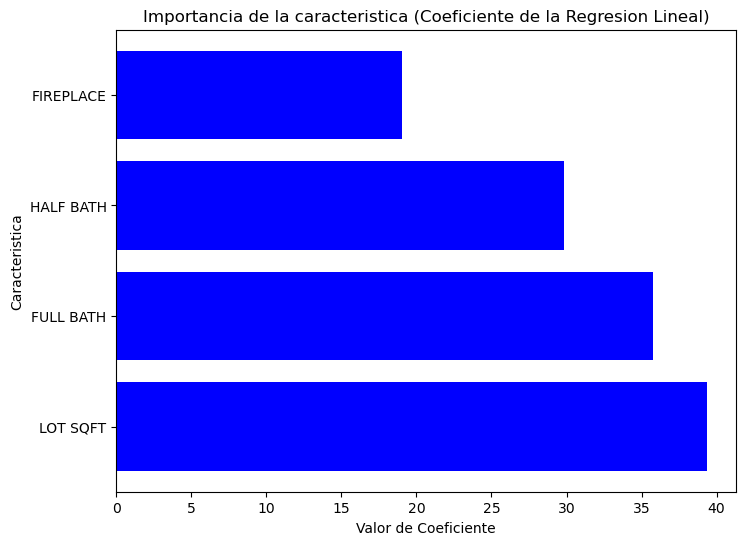

In [328]:
coeficientes_ordenado_df = coeficientes_df.sort_values(by="Coeficiente", ascending=False)

# Create plot
plt.figure(figsize=(8,6))
plt.barh(coeficientes_df["Caracteristica"], coeficientes_ordenado_df["Coeficiente"],color="blue")
plt.xlabel("Valor de Coeficiente")
plt.ylabel("Caracteristica")
plt.title("Importancia de la caracteristica (Coeficiente de la Regresion Lineal)")